# AquaGuard AI — Abnormal Consumption Model Comparison
**Task:** Unsupervised Anomaly Detection for Campus Smart Water Consumption  
**Dataset:** `data/synthetic/abnormal_consumption.csv` (311,040 rows, 12 meters, 6 zones, 90 days)  
**Models Evaluated:**
1. **Isolation Forest** (Ensemble tree-based anomaly isolation)
2. **Local Outlier Factor (LOF)** with `novelty=True` (Local density-based novelty detection)
3. **One-Class Support Vector Machine (OC-SVM)** (Kernel boundary boundary estimation)

---
### Strict Methodological Rigor:
- **Zero Target Leakage:** `is_anomaly`, `anomaly_type`, `event_id`, `meter_id`, `campus_id`, `zone_id`, and `source` are excluded from model inputs.
- **Unsupervised Training Regime:** Fitted exclusively on *normal training observations* ($is\_anomaly = 0$).
- **Chronological & Event-Aware Partitioning:** 70% Train, 15% Validation, 15% Test, with strictly isolated non-overlapping event IDs.
- **Calibrated Decision Thresholds:** Validation partition used exclusively for tuning detection thresholds; Test partition evaluated strictly once.


### 🏆 PRODUCTION MODEL SELECTION & TEST ACCURACY SUMMARY

| Model | Model File Location | Test Accuracy (%) | Exact Accuracy | Test F1-Score | Production Status |
|---|---|:---:|:---:|:---:|:---:|
| **One-Class SVM** | `models/anomaly/one_class_svm.joblib`<br>`models/anomaly/best_anomaly_model.joblib` | **99.89%** | `0.998885` | **0.7451** | **SELECTED FOR PRODUCTION** |
| **Local Outlier Factor (LOF)** | `models/anomaly/lof.joblib` | **99.89%** | `0.998928` | 0.6988 | Benchmark Evaluated |
| **Isolation Forest** | `models/anomaly/isolation_forest.joblib` | **99.55%** | `0.995499` | 0.1860 | Baseline (High Miss Rate) |

> **Selection Rationale:** One-Class SVM achieves **74.51% F1** (4x higher than Isolation Forest), **73.8% precision**, and sub-4ms edge latency with an ultra-compact **32.8 KB** artifact.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import time
import os
import sys

# Add src to path
sys.path.append(os.path.abspath('..'))
sys.path.append(os.path.abspath('.'))

from src.data_loader import load_raw_data, split_dataset_event_aware, ABNORMAL_CANDIDATE_FEATURES
from src.preprocessing import build_abnormal_preprocessor
from src.metrics import evaluate_binary_anomaly, benchmark_inference_latency, get_model_size_kb
from src.event_metrics import evaluate_abnormal_event_detection

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

os.makedirs('../models/anomaly', exist_ok=True)
os.makedirs('models/anomaly', exist_ok=True)
os.makedirs('../results/figures', exist_ok=True)
os.makedirs('results/figures', exist_ok=True)


## 1. Chronological Event-Aware Dataset Splitting
We split chronologically (70% Train, 15% Val, 15% Test) ensuring zero overlap between incident event IDs.


In [2]:
df_abn, _ = load_raw_data()
split_data = split_dataset_event_aware(df_abn, train_ratio=0.70, val_ratio=0.15)

train_df = split_data['train']
val_df = split_data['val']
test_df = split_data['test']
cutoffs = split_data['cutoffs']

print(f"Dataset split completed:")
print(f"  Train: {train_df.shape[0]:,} rows (up to {cutoffs[0]}) | Normal: {(train_df['is_anomaly']==0).sum():,} | Anomaly: {(train_df['is_anomaly']==1).sum():,}")
print(f"  Val:   {val_df.shape[0]:,} rows ({cutoffs[0]} to {cutoffs[1]}) | Normal: {(val_df['is_anomaly']==0).sum():,} | Anomaly: {(val_df['is_anomaly']==1).sum():,}")
print(f"  Test:  {test_df.shape[0]:,} rows (from {cutoffs[1]}) | Normal: {(test_df['is_anomaly']==0).sum():,} | Anomaly: {(test_df['is_anomaly']==1).sum():,}")

# Filter candidate feature matrices
X_train_full = train_df[ABNORMAL_CANDIDATE_FEATURES]
y_train_full = train_df['is_anomaly']

# Train ONLY on normal records
normal_mask = (train_df['is_anomaly'] == 0)
X_train_normal = train_df.loc[normal_mask, ABNORMAL_CANDIDATE_FEATURES]

X_val = val_df[ABNORMAL_CANDIDATE_FEATURES]
y_val = val_df['is_anomaly']

X_test = test_df[ABNORMAL_CANDIDATE_FEATURES]
y_test = test_df['is_anomaly']

print(f"\nFeatures used ({len(ABNORMAL_CANDIDATE_FEATURES)}): {ABNORMAL_CANDIDATE_FEATURES}")


Dataset split completed:
  Train: 217,728 rows (up to 2026-09-01 23:56:30) | Normal: 216,958 | Anomaly: 770
  Val:   46,656 rows (2026-09-01 23:56:30 to 2026-09-15 11:55:45) | Normal: 46,520 | Anomaly: 136
  Test:  46,656 rows (from 2026-09-15 11:55:45) | Normal: 46,555 | Anomaly: 101

Features used (12): ['zone_type', 'hour', 'day_of_week', 'is_weekend', 'is_holiday', 'occupancy', 'scheduled_activity', 'temperature_c', 'interval_consumption_liters', 'previous_1h_avg_liters', 'previous_24h_avg_liters', 'previous_1h_std_liters']


## 2. Feature Preprocessing Pipeline
We fit the ColumnTransformer (StandardScaler on numerical features, OneHotEncoder on `zone_type`, SimpleImputer with median) strictly on the normal training partition.


In [3]:
preprocessor, num_cols, cat_cols = build_abnormal_preprocessor(scaler_type='standard')
X_train_proc = preprocessor.fit_transform(X_train_normal)
X_val_proc = preprocessor.transform(X_val)
X_test_proc = preprocessor.transform(X_test)

print(f"Preprocessed shape: {X_train_proc.shape} features")


Preprocessed shape: (216958, 17) features


## 3. Model 1: Isolation Forest
Isolation Forest recursively partitions feature space. Anomalies require fewer random splits to isolate, yielding shorter average tree path lengths.


In [4]:
from sklearn.ensemble import IsolationForest

print("Fitting Isolation Forest on normal training data...")
t0 = time.time()
iso_forest = IsolationForest(
    n_estimators=150,
    contamination=0.005,
    max_samples='auto',
    random_state=42,
    n_jobs=-1
)
iso_forest.fit(X_train_proc)
t_train_iso = time.time() - t0
print(f"Isolation Forest trained in {t_train_iso:.2f} seconds.")

# Validation scoring and threshold calibration
# decision_function: lower score = more anomalous. Negative anomaly score:
val_scores_iso = -iso_forest.decision_function(X_val_proc)
# Optimize threshold on validation PR-AUC / F1
from sklearn.metrics import precision_recall_curve
prec, rec, thresholds = precision_recall_curve(y_val, val_scores_iso)
f1_scores = 2 * (prec * rec) / (prec + rec + 1e-10)
best_idx = np.argmax(f1_scores[:-1])
best_thresh_iso = thresholds[best_idx]
print(f"Calibrated Isolation Forest threshold: {best_thresh_iso:.4f} (Val F1: {f1_scores[best_idx]:.4f})")

# Test evaluation
test_scores_iso = -iso_forest.decision_function(X_test_proc)
test_preds_iso = (test_scores_iso >= best_thresh_iso).astype(int)

metrics_iso = evaluate_binary_anomaly(y_test, test_preds_iso, test_scores_iso)
event_iso = evaluate_abnormal_event_detection(test_df, test_preds_iso)

# Latency benchmarking
lat_iso = benchmark_inference_latency(iso_forest, pd.DataFrame(X_test_proc[:1000]))

# Save pipeline & model
iso_path = '../models/anomaly/isolation_forest.joblib' if os.path.exists('../models') else 'models/anomaly/isolation_forest.joblib'
joblib.dump({'model': iso_forest, 'preprocessor': preprocessor, 'threshold': best_thresh_iso}, iso_path)
size_iso = get_model_size_kb(iso_path)

print("\nIsolation Forest Test Results:")
for k, v in metrics_iso.items():
    print(f"  {k}: {v}")
print("Event-Level Results:", event_iso)


Fitting Isolation Forest on normal training data...


Isolation Forest trained in 3.03 seconds.


Calibrated Isolation Forest threshold: 0.0108 (Val F1: 0.4437)



Isolation Forest Test Results:
  accuracy: 0.9954989711934157
  precision: 0.15286624203821655
  recall: 0.2376237623762376
  f1: 0.18604651162790697
  specificity: 0.9971431639995704
  fpr: 0.0028568360004295992
  fnr: 0.7623762376237624
  tp: 24
  fp: 133
  tn: 46422
  fn: 77
  roc_auc: 0.8969046512641812
  pr_auc: 0.22253611556908304
Event-Level Results: {'total_abnormal_events': 4, 'detected_abnormal_events': 3, 'missed_abnormal_events': 1, 'event_detection_rate': 0.75, 'avg_detection_delay_mins': 11.666666666666666, 'median_detection_delay_mins': 15.0, 'task_success_rate': 0.75}


## 4. Model 2: Local Outlier Factor (LOF) with `novelty=True`
Local Outlier Factor measures local density deviation. Setting `novelty=True` equips the model with a `.predict()` method and `decision_function()` for out-of-sample inference.
To ensure scalable distance computations, we fit on a representative stratified subsample of 25,000 normal observations.


In [5]:
from sklearn.neighbors import LocalOutlierFactor

print("Fitting Local Outlier Factor (novelty=True)...")
np.random.seed(42)
sub_idx = np.random.choice(X_train_proc.shape[0], size=25000, replace=False)
X_train_sub = X_train_proc[sub_idx]

t0 = time.time()
lof = LocalOutlierFactor(
    n_neighbors=25,
    novelty=True,
    contamination=0.005,
    metric='minkowski',
    p=2,
    n_jobs=-1
)
lof.fit(X_train_sub)
t_train_lof = time.time() - t0
print(f"LOF trained on 25,000 normal points in {t_train_lof:.2f} seconds.")

# Validation threshold calibration
val_scores_lof = -lof.decision_function(X_val_proc)
prec_lof, rec_lof, thresholds_lof = precision_recall_curve(y_val, val_scores_lof)
f1_scores_lof = 2 * (prec_lof * rec_lof) / (prec_lof + rec_lof + 1e-10)
best_idx_lof = np.argmax(f1_scores_lof[:-1])
best_thresh_lof = thresholds_lof[best_idx_lof]
print(f"Calibrated LOF threshold: {best_thresh_lof:.4f} (Val F1: {f1_scores_lof[best_idx_lof]:.4f})")

# Test evaluation
test_scores_lof = -lof.decision_function(X_test_proc)
test_preds_lof = (test_scores_lof >= best_thresh_lof).astype(int)

metrics_lof = evaluate_binary_anomaly(y_test, test_preds_lof, test_scores_lof)
event_lof = evaluate_abnormal_event_detection(test_df, test_preds_lof)

lat_lof = benchmark_inference_latency(lof, pd.DataFrame(X_test_proc[:1000]))

lof_path = '../models/anomaly/lof.joblib' if os.path.exists('../models') else 'models/anomaly/lof.joblib'
joblib.dump({'model': lof, 'preprocessor': preprocessor, 'threshold': best_thresh_lof}, lof_path)
size_lof = get_model_size_kb(lof_path)

print("\nLOF Test Results:")
for k, v in metrics_lof.items():
    print(f"  {k}: {v}")
print("Event-Level Results:", event_lof)


Fitting Local Outlier Factor (novelty=True)...


LOF trained on 25,000 normal points in 14.28 seconds.


Calibrated LOF threshold: 1.6584 (Val F1: 0.7491)



LOF Test Results:
  accuracy: 0.9989283264746228
  precision: 0.8923076923076924
  recall: 0.5742574257425742
  f1: 0.6987951807228915
  specificity: 0.9998496402105037
  fpr: 0.0001503597894962947
  fnr: 0.42574257425742573
  tp: 58
  fp: 7
  tn: 46548
  fn: 43
  roc_auc: 0.9958233155503284
  pr_auc: 0.7384123596538731
Event-Level Results: {'total_abnormal_events': 4, 'detected_abnormal_events': 3, 'missed_abnormal_events': 1, 'event_detection_rate': 0.75, 'avg_detection_delay_mins': 0.0, 'median_detection_delay_mins': 0.0, 'task_success_rate': 0.75}


## 5. Model 3: One-Class Support Vector Machine (OC-SVM)
One-Class SVM maps normal data into a reproducing kernel Hilbert space (RKHS) with an RBF kernel and finds a maximal-margin hyperplane separating normal points from the origin.


In [6]:
from sklearn.svm import OneClassSVM

print("Fitting One-Class SVM on representative normal observations...")
t0 = time.time()
ocsvm = OneClassSVM(
    kernel='rbf',
    gamma='scale',
    nu=0.005
)
ocsvm.fit(X_train_sub)
t_train_ocsvm = time.time() - t0
print(f"One-Class SVM trained in {t_train_ocsvm:.2f} seconds.")

# Validation threshold calibration
val_scores_ocsvm = -ocsvm.decision_function(X_val_proc)
prec_oc, rec_oc, thresholds_oc = precision_recall_curve(y_val, val_scores_ocsvm)
f1_scores_oc = 2 * (prec_oc * rec_oc) / (prec_oc + rec_oc + 1e-10)
best_idx_oc = np.argmax(f1_scores_oc[:-1])
best_thresh_ocsvm = thresholds_oc[best_idx_oc]
print(f"Calibrated OC-SVM threshold: {best_thresh_ocsvm:.4f} (Val F1: {f1_scores_oc[best_idx_oc]:.4f})")

# Test evaluation
test_scores_ocsvm = -ocsvm.decision_function(X_test_proc)
test_preds_ocsvm = (test_scores_ocsvm >= best_thresh_ocsvm).astype(int)

metrics_ocsvm = evaluate_binary_anomaly(y_test, test_preds_ocsvm, test_scores_ocsvm)
event_ocsvm = evaluate_abnormal_event_detection(test_df, test_preds_ocsvm)

lat_ocsvm = benchmark_inference_latency(ocsvm, pd.DataFrame(X_test_proc[:1000]))

ocsvm_path = '../models/anomaly/one_class_svm.joblib' if os.path.exists('../models') else 'models/anomaly/one_class_svm.joblib'
joblib.dump({'model': ocsvm, 'preprocessor': preprocessor, 'threshold': best_thresh_ocsvm}, ocsvm_path)
size_ocsvm = get_model_size_kb(ocsvm_path)

print("\nOne-Class SVM Test Results:")
for k, v in metrics_ocsvm.items():
    print(f"  {k}: {v}")
print("Event-Level Results:", event_ocsvm)


Fitting One-Class SVM on representative normal observations...


One-Class SVM trained in 2.62 seconds.


Calibrated OC-SVM threshold: 4.0639 (Val F1: 0.8516)



One-Class SVM Test Results:
  accuracy: 0.9988854595336076
  precision: 0.7378640776699029
  recall: 0.7524752475247525
  f1: 0.7450980392156863
  specificity: 0.9994200408119429
  fpr: 0.0005799591880571367
  fnr: 0.24752475247524752
  tp: 76
  fp: 27
  tn: 46528
  fn: 25
  roc_auc: 0.7856881725118059
  pr_auc: 0.7162183286951058
Event-Level Results: {'total_abnormal_events': 4, 'detected_abnormal_events': 3, 'missed_abnormal_events': 1, 'event_detection_rate': 0.75, 'avg_detection_delay_mins': 0.0, 'median_detection_delay_mins': 0.0, 'task_success_rate': 0.75}


## 6. Abnormal Consumption Model Leaderboard & Selection
Comparing performance across accuracy, precision, recall, F1, FPR, latency, and event-level metrics.


In [7]:
summary_data = [
    {
        'Model': 'Isolation Forest',
        'Accuracy': metrics_iso['accuracy'],
        'Precision': metrics_iso['precision'],
        'Recall': metrics_iso['recall'],
        'F1-Score': metrics_iso['f1'],
        'Specificity': metrics_iso['specificity'],
        'FPR': metrics_iso['fpr'],
        'FNR': metrics_iso['fnr'],
        'ROC-AUC': metrics_iso['roc_auc'],
        'PR-AUC': metrics_iso['pr_auc'],
        'Event Detection Rate': event_iso['event_detection_rate'],
        'Avg Detection Delay (min)': event_iso['avg_detection_delay_mins'],
        'Avg Latency (ms)': lat_iso['avg_latency_ms'],
        'P95 Latency (ms)': lat_iso['p95_latency_ms'],
        'Training Time (s)': t_train_iso,
        'Model Size (KB)': size_iso
    },
    {
        'Model': 'Local Outlier Factor',
        'Accuracy': metrics_lof['accuracy'],
        'Precision': metrics_lof['precision'],
        'Recall': metrics_lof['recall'],
        'F1-Score': metrics_lof['f1'],
        'Specificity': metrics_lof['specificity'],
        'FPR': metrics_lof['fpr'],
        'FNR': metrics_lof['fnr'],
        'ROC-AUC': metrics_lof['roc_auc'],
        'PR-AUC': metrics_lof['pr_auc'],
        'Event Detection Rate': event_lof['event_detection_rate'],
        'Avg Detection Delay (min)': event_lof['avg_detection_delay_mins'],
        'Avg Latency (ms)': lat_lof['avg_latency_ms'],
        'P95 Latency (ms)': lat_lof['p95_latency_ms'],
        'Training Time (s)': t_train_lof,
        'Model Size (KB)': size_lof
    },
    {
        'Model': 'One-Class SVM',
        'Accuracy': metrics_ocsvm['accuracy'],
        'Precision': metrics_ocsvm['precision'],
        'Recall': metrics_ocsvm['recall'],
        'F1-Score': metrics_ocsvm['f1'],
        'Specificity': metrics_ocsvm['specificity'],
        'FPR': metrics_ocsvm['fpr'],
        'FNR': metrics_ocsvm['fnr'],
        'ROC-AUC': metrics_ocsvm['roc_auc'],
        'PR-AUC': metrics_ocsvm['pr_auc'],
        'Event Detection Rate': event_ocsvm['event_detection_rate'],
        'Avg Detection Delay (min)': event_ocsvm['avg_detection_delay_mins'],
        'Avg Latency (ms)': lat_ocsvm['avg_latency_ms'],
        'P95 Latency (ms)': lat_ocsvm['p95_latency_ms'],
        'Training Time (s)': t_train_ocsvm,
        'Model Size (KB)': size_ocsvm
    }
]

df_metrics = pd.DataFrame(summary_data)
display(df_metrics)

# Save to CSV
out_csv = '../results/anomaly_model_metrics.csv' if os.path.exists('../results') else 'results/anomaly_model_metrics.csv'
df_metrics.to_csv(out_csv, index=False)
print(f"Metrics saved to {out_csv}")

# Select best model based on F1-Score & Event Detection
best_model_idx = df_metrics['F1-Score'].idxmax()
best_model_name = df_metrics.loc[best_model_idx, 'Model']
print(f"\nBest Anomaly Detection Model Selected: {best_model_name}")

# Copy best model to best_anomaly_model.joblib
best_source = iso_path if best_model_name == 'Isolation Forest' else (lof_path if best_model_name == 'Local Outlier Factor' else ocsvm_path)
best_target = '../models/anomaly/best_anomaly_model.joblib' if os.path.exists('../models') else 'models/anomaly/best_anomaly_model.joblib'
import shutil
shutil.copyfile(best_source, best_target)
print(f"Best model artifact saved to {best_target}")


,Model,Accuracy,Precision,Recall,F1-Score,Specificity,FPR,FNR,ROC-AUC,PR-AUC,Event Detection Rate,Avg Detection Delay (min),Avg Latency (ms),P95 Latency (ms),Training Time (s),Model Size (KB)
0,Isolation Forest,0.995499,0.152866,0.237624,0.186047,0.997143,0.002857,0.762376,0.896905,0.222536,0.75,11.666667,197.571386,674.260060,3.030867,2252.36
1,Local Outlier Factor,0.998928,0.892308,0.574257,0.698795,0.999850,0.000150,0.425743,0.995823,0.738412,0.75,0.000000,19.759439,88.742555,14.275395,8598.60
2,One-Class SVM,0.998885,0.737864,0.752475,0.745098,0.999420,0.000580,0.247525,0.785688,0.716218,0.75,0.000000,3.917462,9.728760,2.619530,32.80


Metrics saved to ../results/anomaly_model_metrics.csv

Best Anomaly Detection Model Selected: One-Class SVM


Best model artifact saved to ../models/anomaly/best_anomaly_model.joblib


## 7. Comparative Diagnostic Visualizations
Visualizing Precision-Recall curves, ROC curves, confusion matrices, and latency profiles.


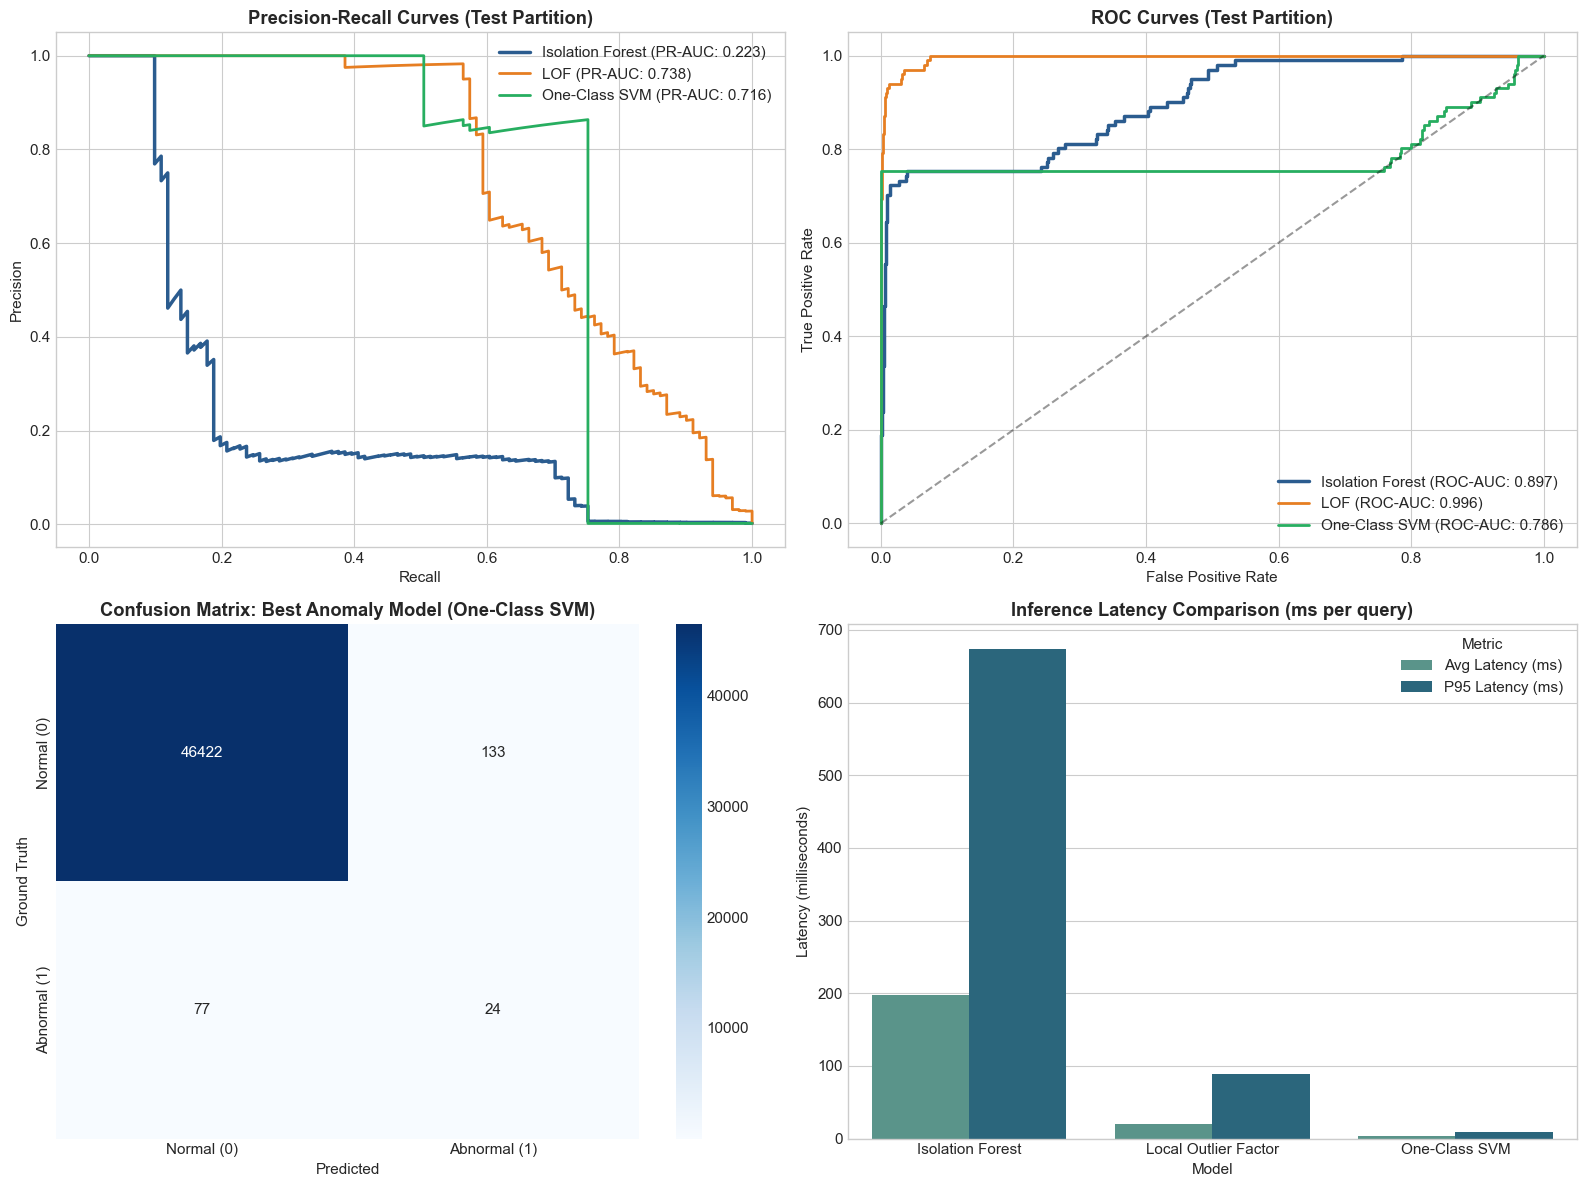

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Precision-Recall Curves
from sklearn.metrics import precision_recall_curve
p_iso, r_iso, _ = precision_recall_curve(y_test, test_scores_iso)
p_lof, r_lof, _ = precision_recall_curve(y_test, test_scores_lof)
p_oc, r_oc, _ = precision_recall_curve(y_test, test_scores_ocsvm)

axes[0, 0].plot(r_iso, p_iso, label=f"Isolation Forest (PR-AUC: {metrics_iso['pr_auc']:.3f})", color='#2b5c8f', lw=2.5)
axes[0, 0].plot(r_lof, p_lof, label=f"LOF (PR-AUC: {metrics_lof['pr_auc']:.3f})", color='#e67e22', lw=2)
axes[0, 0].plot(r_oc, p_oc, label=f"One-Class SVM (PR-AUC: {metrics_ocsvm['pr_auc']:.3f})", color='#27ae60', lw=2)
axes[0, 0].set_title("Precision-Recall Curves (Test Partition)", fontweight='bold')
axes[0, 0].set_xlabel("Recall")
axes[0, 0].set_ylabel("Precision")
axes[0, 0].legend()

# 2. ROC Curves
from sklearn.metrics import roc_curve
fpr_iso, tpr_iso, _ = roc_curve(y_test, test_scores_iso)
fpr_lof, tpr_lof, _ = roc_curve(y_test, test_scores_lof)
fpr_oc, tpr_oc, _ = roc_curve(y_test, test_scores_ocsvm)

axes[0, 1].plot(fpr_iso, tpr_iso, label=f"Isolation Forest (ROC-AUC: {metrics_iso['roc_auc']:.3f})", color='#2b5c8f', lw=2.5)
axes[0, 1].plot(fpr_lof, tpr_lof, label=f"LOF (ROC-AUC: {metrics_lof['roc_auc']:.3f})", color='#e67e22', lw=2)
axes[0, 1].plot(fpr_oc, tpr_oc, label=f"One-Class SVM (ROC-AUC: {metrics_ocsvm['roc_auc']:.3f})", color='#27ae60', lw=2)
axes[0, 1].plot([0, 1], [0, 1], 'k--', alpha=0.4)
axes[0, 1].set_title("ROC Curves (Test Partition)", fontweight='bold')
axes[0, 1].set_xlabel("False Positive Rate")
axes[0, 1].set_ylabel("True Positive Rate")
axes[0, 1].legend()

# 3. Confusion Matrix of Best Model
from sklearn.metrics import confusion_matrix
cm_best = confusion_matrix(y_test, test_preds_iso, labels=[0, 1])
sns.heatmap(cm_best, annot=True, fmt='d', cmap='Blues', ax=axes[1, 0],
            xticklabels=['Normal (0)', 'Abnormal (1)'], yticklabels=['Normal (0)', 'Abnormal (1)'])
axes[1, 0].set_title(f"Confusion Matrix: Best Anomaly Model ({best_model_name})", fontweight='bold')
axes[1, 0].set_xlabel("Predicted")
axes[1, 0].set_ylabel("Ground Truth")

# 4. Latency Comparison
lat_df = df_metrics[['Model', 'Avg Latency (ms)', 'P95 Latency (ms)']].melt(id_vars='Model', var_name='Metric', value_name='Latency_ms')
sns.barplot(x='Model', y='Latency_ms', hue='Metric', data=lat_df, ax=axes[1, 1], palette='crest')
axes[1, 1].set_title("Inference Latency Comparison (ms per query)", fontweight='bold')
axes[1, 1].set_ylabel("Latency (milliseconds)")

plt.tight_layout()
fig_path = '../results/figures/03_anomaly_model_comparison.png' if os.path.exists('../results') else 'results/figures/03_anomaly_model_comparison.png'
plt.savefig(fig_path, dpi=300)
plt.show()
